In [13]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.models import load_model
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

In [14]:
train_dir = r"D:\DR AND GLAUCOMA DETECTION PROJECT\datasets\Split_Dataset\train"
validation_dir = r"D:\DR AND GLAUCOMA DETECTION PROJECT\datasets\Split_Dataset\validation"
test_dir = r"D:\DR AND GLAUCOMA DETECTION PROJECT\datasets\Split_Dataset\test"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

In [15]:
train_dataset = image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True
)

validation_dataset = image_dataset_from_directory(
    validation_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

test_dataset = image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

Found 15442 files belonging to 3 classes.
Found 1930 files belonging to 3 classes.
Found 1932 files belonging to 3 classes.


In [16]:
from tensorflow.keras.models import load_model

model = load_model(
    r"D:\DR AND GLAUCOMA DETECTION PROJECT\models\resnet50_best.keras"
)

print("Model loaded successfully!")

Model loaded successfully!


In [17]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,606,155 (90.05 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 12,296 (48.04 KB)

In [18]:
# Find the ResNet50 base model inside the loaded model
for i, layer in enumerate(model.layers):
    print(i, layer.name, type(layer))

0 input_layer_1 <class 'keras.src.layers.core.input_layer.InputLayer'>
1 sequential <class 'keras.src.models.sequential.Sequential'>
2 resnet50 <class 'keras.src.models.functional.Functional'>
3 global_average_pooling2d <class 'keras.src.layers.pooling.global_average_pooling2d.GlobalAveragePooling2D'>
4 dropout <class 'keras.src.layers.regularization.dropout.Dropout'>
5 dense <class 'keras.src.layers.core.dense.Dense'>


In [19]:
base_model = model.layers[2]

# Unfreeze the ResNet50 model
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))

Trainable layers: 30


In [20]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [21]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    r"D:\DR AND GLAUCOMA DETECTION PROJECT\models\resnet50_finetuned.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

In [13]:
print(class_weights)

NameError: name 'class_weights' is not defined

In [22]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_names = train_dataset.class_names
print(class_names)

labels = []

for _, y in train_dataset:
    labels.extend(np.argmax(y.numpy(), axis=1))

labels = np.array(labels)

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels),
    y=labels
)

class_weights = dict(enumerate(weights))

print(class_weights)

['diabetic_retinopathy', 'glaucoma', 'normal']
{0: np.float64(0.6356301967564008), 1: np.float64(1.3499431768511234), 2: np.float64(1.4577551213065232)}


In [23]:
print(class_weights)

{0: np.float64(0.6356301967564008), 1: np.float64(1.3499431768511234), 2: np.float64(1.4577551213065232)}


In [17]:
history_finetune = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    class_weight=class_weights,
    callbacks=[early_stop, checkpoint],
    verbose=1
)

Epoch 1/5
483/483 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8919 - loss: 0.1840
Epoch 1: val_accuracy improved from 0.88964 to 0.89896, saving model to D:\DR AND GLAUCOMA DETECTION PROJECT\models\resnet50_finetuned.keras

Epoch 1: finished saving model to D:\DR AND GLAUCOMA DETECTION PROJECT\models\resnet50_finetuned.keras
483/483 ━━━━━━━━━━━━━━━━━━━━ 2346s 5s/step - accuracy: 0.8919 - loss: 0.1840 - val_accuracy: 0.8990 - val_loss: 0.1894
Epoch 2/5
483/483 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8966 - loss: 0.1725
Epoch 2: val_accuracy did not improve from 0.89896
483/483 ━━━━━━━━━━━━━━━━━━━━ 2312s 5s/step - accuracy: 0.8966 - loss: 0.1725 - val_accuracy: 0.8990 - val_loss: 0.1902
Epoch 3/5
483/483 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9058 - loss: 0.1564
Epoch 3: val_accuracy improved from 0.89896 to 0.91036, saving model to D:\DR AND GLAUCOMA DETECTION PROJECT\models\resnet50_finetuned.keras

Epoch 3: finished saving model to D:\DR AND GLAUCOMA DETECTION PROJECT\m

In [25]:
from tensorflow.keras.models import load_model

best_model = load_model(
    r"D:\DR AND GLAUCOMA DETECTION PROJECT\models\resnet50_finetuned.keras"
)

test_loss, test_accuracy = best_model.evaluate(test_dataset)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

61/61 ━━━━━━━━━━━━━━━━━━━━ 192s 3s/step - accuracy: 0.9161 - loss: 0.1776
Test Loss: 0.1776
Test Accuracy: 0.9161


In [26]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

true_labels = []
predicted_labels = []

for images, labels in test_dataset:
    predictions = best_model.predict(images, verbose=0)

    true_labels.extend(np.argmax(labels.numpy(), axis=1))
    predicted_labels.extend(np.argmax(predictions, axis=1))

print(classification_report(
    true_labels,
    predicted_labels,
    target_names=test_dataset.class_names
))

                      precision    recall  f1-score   support

diabetic_retinopathy       0.93      0.91      0.92      1013
            glaucoma       1.00      1.00      1.00       477
              normal       0.80      0.85      0.82       442

            accuracy                           0.92      1932
           macro avg       0.91      0.92      0.91      1932
        weighted avg       0.92      0.92      0.92      1932



In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(true_labels, predicted_labels)
precision = precision_score(true_labels, predicted_labels, average="weighted")
recall = recall_score(true_labels, predicted_labels, average="weighted")
f1 = f1_score(true_labels, predicted_labels, average="weighted")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

Accuracy : 0.9161
Precision: 0.9183
Recall   : 0.9161
F1-Score : 0.9169


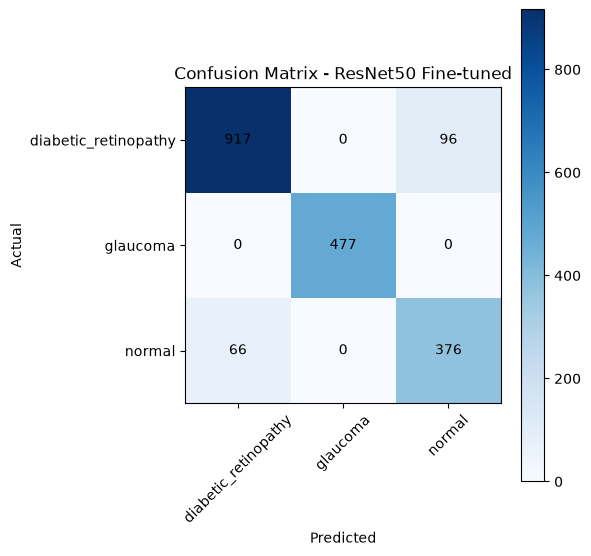

In [28]:
import matplotlib.pyplot as plt

cm = confusion_matrix(true_labels, predicted_labels)

plt.figure(figsize=(6,6))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix - ResNet50 Fine-tuned")
plt.colorbar()

classes = test_dataset.class_names
plt.xticks(range(len(classes)), classes, rotation=45)
plt.yticks(range(len(classes)), classes)

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [4]:
dir()

['In',
 'Out',
 '_',
 '__',
 '___',
 '__builtin__',
 '__builtins__',
 '__doc__',
 '__loader__',
 '__name__',
 '__package__',
 '__spec__',
 '__vsc_ipynb_file__',
 '_dh',
 '_i',
 '_i1',
 '_i2',
 '_i3',
 '_i4',
 '_ih',
 '_ii',
 '_iii',
 '_oh',
 'exit',
 'get_ipython',
 'open',
 'plt',
 'quit']

NameError: name 'history_finetune' is not defined

In [6]:
history =

SyntaxError: invalid syntax (1960249463.py, line 1)

In [10]:
from tensorflow.keras.models import load_model

model = load_model(r"D:\DR AND GLAUCOMA DETECTION PROJECT\models\resnet50_best.keras")

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,606,155 (90.05 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 12,296 (48.04 KB)

In [29]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Diabetic Retinopathy", "Glaucoma"],
    output_dict=True
)

NameError: name 'y_true' is not defined

In [30]:
print(test_dataset)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 3), dtype=tf.float32, name=None))>


In [31]:
import numpy as np

# True labels
y_true = np.concatenate([y for x, y in test_dataset], axis=0)
y_true = np.argmax(y_true, axis=1)

# Predicted probabilities
y_pred_prob = model.predict(test_dataset)

# Predicted labels
y_pred = np.argmax(y_pred_prob, axis=1)

61/61 ━━━━━━━━━━━━━━━━━━━━ 223s 4s/step


In [32]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Diabetic Retinopathy", "Glaucoma"]
))

                      precision    recall  f1-score   support

              Normal       0.88      0.83      0.86      1013
Diabetic Retinopathy       0.99      0.93      0.96       477
            Glaucoma       0.63      0.74      0.68       442

            accuracy                           0.84      1932
           macro avg       0.83      0.83      0.83      1932
        weighted avg       0.85      0.84      0.84      1932



In [33]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Diabetic Retinopathy", "Glaucoma"],
    output_dict=True
)

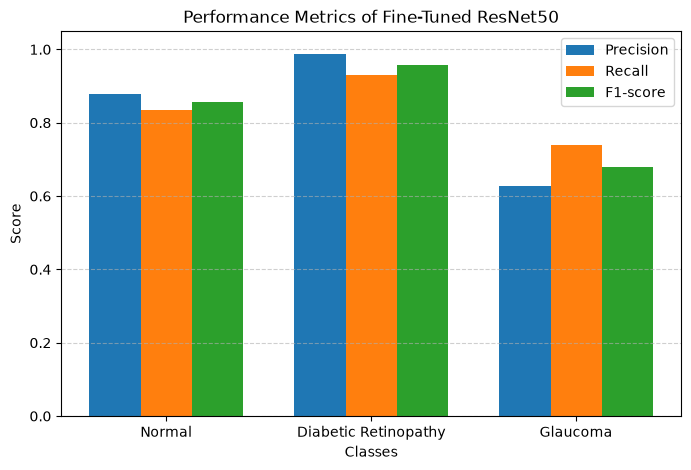

In [34]:
import matplotlib.pyplot as plt
import numpy as np

classes = ["Normal", "Diabetic Retinopathy", "Glaucoma"]

precision = [report[c]["precision"] for c in classes]
recall = [report[c]["recall"] for c in classes]
f1 = [report[c]["f1-score"] for c in classes]

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(8,5))

plt.bar(x - width, precision, width, label='Precision')
plt.bar(x, recall, width, label='Recall')
plt.bar(x + width, f1, width, label='F1-score')

plt.xticks(x, classes)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.xlabel("Classes")
plt.title("Performance Metrics of Fine-Tuned ResNet50")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()

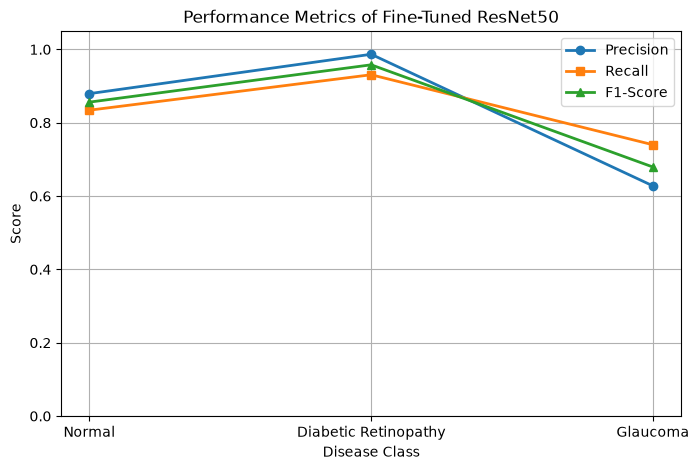

In [35]:
import matplotlib.pyplot as plt

classes = ["Normal", "Diabetic Retinopathy", "Glaucoma"]

precision = [report[c]["precision"] for c in classes]
recall = [report[c]["recall"] for c in classes]
f1 = [report[c]["f1-score"] for c in classes]

plt.figure(figsize=(8,5))

plt.plot(classes, precision, marker='o', linewidth=2, label='Precision')
plt.plot(classes, recall, marker='s', linewidth=2, label='Recall')
plt.plot(classes, f1, marker='^', linewidth=2, label='F1-Score')

plt.ylim(0,1.05)
plt.xlabel("Disease Class")
plt.ylabel("Score")
plt.title("Performance Metrics of Fine-Tuned ResNet50")
plt.grid(True)
plt.legend()

plt.show()

In [37]:
import numpy as np

# True labels
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

# Prediction probabilities
y_score = model.predict(test_dataset)

61/61 ━━━━━━━━━━━━━━━━━━━━ 179s 3s/step


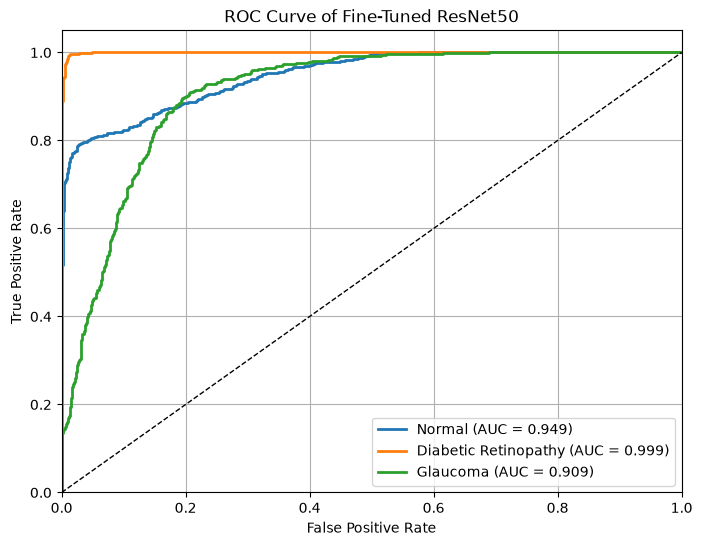

In [38]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

class_names = ["Normal", "Diabetic Retinopathy", "Glaucoma"]

plt.figure(figsize=(8,6))

for i in range(3):
    fpr, tpr, _ = roc_curve(y_true[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, linewidth=2,
             label=f"{class_names[i]} (AUC = {roc_auc:.3f})")

# Random classifier line
plt.plot([0,1], [0,1], 'k--', linewidth=1)

plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve of Fine-Tuned ResNet50")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()

In [39]:
import numpy as np

# True labels (one-hot encoded)
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

# Predicted probabilities
y_score = model.predict(test_dataset)

61/61 ━━━━━━━━━━━━━━━━━━━━ 175s 3s/step


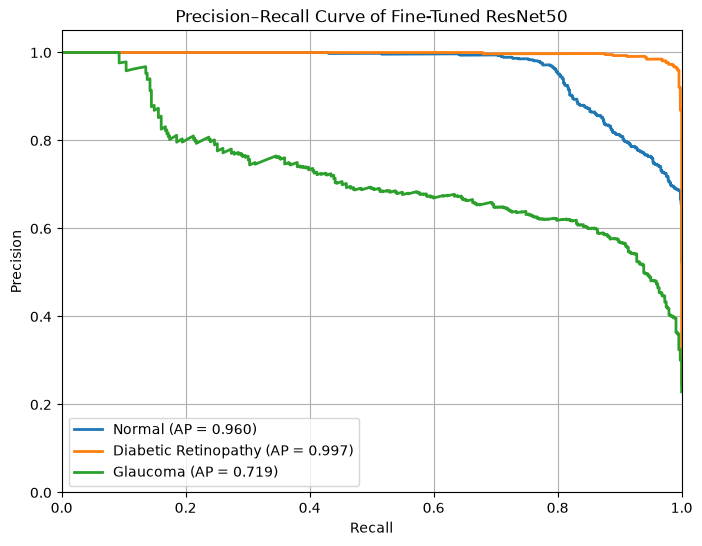

In [40]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

class_names = ["Normal", "Diabetic Retinopathy", "Glaucoma"]

plt.figure(figsize=(8,6))

for i in range(3):
    precision, recall, _ = precision_recall_curve(y_true[:, i], y_score[:, i])
    ap = average_precision_score(y_true[:, i], y_score[:, i])

    plt.plot(recall, precision, linewidth=2,
             label=f"{class_names[i]} (AP = {ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve of Fine-Tuned ResNet50")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.grid(True)
plt.legend(loc="lower left")

# Save before showing (optional)
plt.savefig("precision_recall_curve.png", dpi=300, bbox_inches="tight")

plt.show()

In [42]:
import pickle
import matplotlib.pyplot as plt

# Load saved training history
with open("history_finetune.pkl", "rb") as f:
    history = pickle.load(f)

# Check available keys
print(history.keys())

EOFError: Ran out of input

In [43]:
import os

file_path = "history_finetune.pkl"

print("File size:", os.path.getsize(file_path), "bytes")

File size: 0 bytes
